# Air track, two carts: friction from single-cart decay and from energy loss

Three measurements:
1. cart 1 oscillates, cart 2 is fixed;
2. cart 2 oscillates, cart 1 is fixed;
3. both carts oscillate together.

Runs 1 and 2 give the frequency and quality factor of each cart. Run 3 gives $b_1, b_2$ from the energy decay, which is compared with runs 1 and 2.

Each file: CSV with time and the positions of the two carts in encoder counts.

## Theory

$x_1, x_2$: displacements from equilibrium. Spring $k_1$: wall – cart 1, $k_{12}$: cart 1 – cart 2, $k_2$: cart 2 – wall. Viscous friction $-b_i v_i$.

**Single cart** (the other one fixed): cart $i$ sits on springs $k_i$ and $k_{12}$:
$$m_i\ddot x_i + b_i\dot x_i + (k_i+k_{12})\,x_i = 0 \;\Rightarrow\; x_i = A e^{-\gamma t}\cos(\omega_d t+\varphi) + x_0$$
$$\omega_i = \sqrt{\omega_d^2+\gamma^2},\qquad Q_i = \frac{\omega_i}{2\gamma},\qquad b_i = 2\gamma\, m_i^{\rm eff}$$
Part of the spring mass moves with the cart, so the measured frequency is a bit lower than $\sqrt{(k_i+k_{12})/m_i}$. We use the effective mass
$$m_i^{\rm eff} = \frac{k_i+k_{12}}{\omega_i^2}.$$

**Both carts**: energy
$$E = \tfrac12 m_1^{\rm eff} v_1^2 + \tfrac12 m_2^{\rm eff} v_2^2 + \tfrac12 k_1 x_1^2 + \tfrac12 k_{12}(x_2-x_1)^2 + \tfrac12 k_2 x_2^2,\qquad \dot E = -b_1 v_1^2 - b_2 v_2^2$$
$$E(t) = E_0 - b_1\int_0^t v_1^2\,dt' - b_2\int_0^t v_2^2\,dt'$$
fitted with `curve_fit` (linear in $b_1, b_2, E_0$). Tracking noise adds a constant $\sigma_v^2$ to $v_i^2$; it is estimated from the positions and subtracted.

$b_1, b_2$ are separated only if $v_2^2/v_1^2$ changes during run 3 (both normal modes excited, energy moving between the carts). A good start: displace one cart only.

Approximation: the mass of spring $k_{12}$ really couples the carts a little (off-diagonal mass term); here it is split between the carts through $m^{\rm eff}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter, savgol_coeffs
from scipy.integrate import cumulative_trapezoid, solve_ivp
from scipy.optimize import curve_fit

FILES = {"cart1": "cart1.txt",   # cart 1 oscillates, cart 2 fixed
         "cart2": "cart2.txt",   # cart 2 oscillates, cart 1 fixed
         "both":  "cart1_and_cart2.txt"}         # both carts oscillate
SKIP_ROWS = 1               # header lines
COLS = (1, 3, 4)            # columns: time [s], cart 1 [counts], cart 2 [counts]
COUNTS_TO_M = 0.53e-3          # metres per count
SMOOTH_X_S = 0.2            # smoothing window for positions, s
MOTION_START = 0.01         # data used from the moment |v| first exceeds this (and 5x velocity noise), m/s

m1, m2 = 0.2149, 0.2151       # cart masses, kg
k1, k2, k12 = 4.30, 6.78, 9.00 # spring constants, N/m

USE_SYNTHETIC = False                # True: simulate the three runs with known values to test the method
Q1_TRUE, Q2_TRUE = 45, 57          # cart quality factors, synthetic only
DM_TRUE = (0.008, 0.010)             # spring mass added to each cart, kg, synthetic only
NOISE_COUNTS = 3                     # tracking noise, counts, synthetic only

In [3]:
# ---- synthetic data (only if USE_SYNTHETIC) ----
if USE_SYNTHETIC:
    mt = (m1 + DM_TRUE[0], m2 + DM_TRUE[1])
    bt = (np.sqrt(mt[0] * (k1 + k12)) / Q1_TRUE, np.sqrt(mt[1] * (k2 + k12)) / Q2_TRUE)
    rng = np.random.default_rng(0)

    def simulate(x10, x20, fixed=None):
        def rhs(t, y):
            x1, x2, v1, v2 = y
            a1 = 0 if fixed == 1 else (-k1 * x1 - k12 * (x1 - x2) - bt[0] * v1) / mt[0]
            a2 = 0 if fixed == 2 else (-k2 * x2 - k12 * (x2 - x1) - bt[1] * v2) / mt[1]
            return [v1, v2, a1, a2]
        tt = np.arange(0, 60, 0.02)
        s = solve_ivp(rhs, (0, tt[-1]), [x10, x20, 0, 0], t_eval=tt, rtol=1e-9, atol=1e-12)
        t = np.concatenate([np.arange(-2, 0, 0.02), tt])            # 2 s at rest before release
        y1 = np.concatenate([np.full(100, x10), s.y[0]]) + 0.3      # arbitrary zero of the encoder
        y2 = np.concatenate([np.full(100, x20), s.y[1]]) + 0.6
        q = lambda y: np.round(y / COUNTS_TO_M + rng.normal(0, NOISE_COUNTS, t.size)) * COUNTS_TO_M
        return t, q(y1), q(y2)

    SYN = {"cart1": simulate(0.05, 0.0, fixed=2),
           "cart2": simulate(0.0, 0.05, fixed=1),
           "both":  simulate(0.05, 0.0)}


# ---- helpers ----
def load(name):
    """time [s], x1 [m], x2 [m]"""
    if USE_SYNTHETIC:
        return SYN[name]
    t, c1, c2 = np.loadtxt(FILES[name],  skiprows=SKIP_ROWS, usecols=COLS, unpack=True)
    return t, c1 * COUNTS_TO_M, c2 * COUNTS_TO_M


def smooth_and_diff(t, x):
    """smoothed position, velocity, and velocity noise variance"""
    dt = t[1] - t[0]
    w = max(int(round(SMOOTH_X_S / dt)) | 1, 5)
    xs = savgol_filter(x, w, 3)
    v = savgol_filter(x, w, 3, deriv=1, delta=dt)
    h = savgol_coeffs(w, 3)[w // 2]
    d = savgol_coeffs(w, 3, deriv=1, delta=dt)
    nv = np.var(x - xs) / (1 - h) * np.sum(d**2)
    return xs, v, nv


def motion_start(t, v, nv):
    """first index where |v| clearly exceeds the noise; filter edge samples are skipped"""
    w = max(int(round(SMOOTH_X_S / (t[1] - t[0]))) | 1, 5)
    moving = np.abs(v) > max(MOTION_START, 5 * np.sqrt(nv))
    moving[:w] = False
    idx = np.flatnonzero(moving)
    return idx[0] if idx.size else len(v)


def damped(t, A, g, w, phi, x0):
    return A * np.exp(-g * t) * np.cos(w * t + phi) + x0


def fit_single(t, x):
    t = t - t[0]
    y = x - x.mean()
    n = 16 * len(y)
    F = np.abs(np.fft.rfft(y * np.hanning(len(y)), n))
    w_guess = 2 * np.pi * np.fft.rfftfreq(n, t[1] - t[0])[np.argmax(F[1:]) + 1]
    best = None
    for phi in np.linspace(0, 2 * np.pi, 8, endpoint=False):
        try:
            p, c = curve_fit(damped, t, x, p0=[np.abs(y).max(), 0.01, w_guess, phi, x.mean()])
        except RuntimeError:
            continue
        r = np.sum((damped(t, *p) - x) ** 2)
        if best is None or r < best[0]:
            best = (r, p, c)
    _, p, c = best
    A, g, wd, phi, x0 = p
    dg, dwd = np.sqrt(np.diag(c))[[1, 2]]
    w0 = np.sqrt(wd**2 + g**2)
    return dict(t=t, x=x, p=p, g=g, dg=dg, w0=w0, dw0=dwd, Q=w0 / (2 * g), dQ=w0 / (2 * g) * dg / g)

## Runs 1 and 2: each cart alone

cart 1: f = 1.2053 Hz (nominal 1.2521),  m_eff = 231.9 ± 0.0 g,  Q = 44.9 ± 0.0,  b = 3.908e-02 ± 2.1e-05 kg/s
cart 2: f = 1.3263 Hz (nominal 1.3632),  m_eff = 227.2 ± 0.0 g,  Q = 56.8 ± 0.0,  b = 3.333e-02 ± 2.4e-05 kg/s


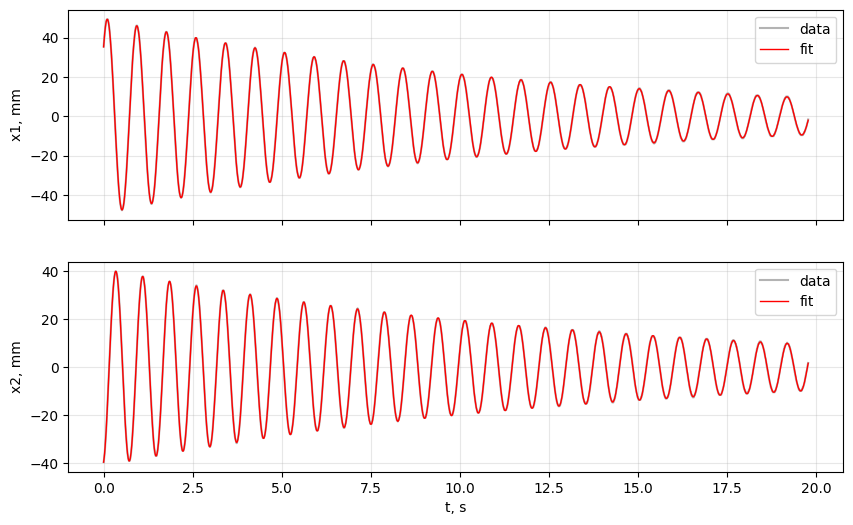

In [5]:
single = {}
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for i, (name, m, k) in enumerate([("cart1", m1, k1), ("cart2", m2, k2)]):
    t, x1, x2 = load(name)
    x = (x1, x2)[i]
    xs, v, nv = smooth_and_diff(t, x)
    i0 = motion_start(t, v, nv)
    r = fit_single(t[i0:], x[i0:])
    r["m_eff"] = (k + k12) / r["w0"] ** 2
    r["dm_eff"] = r["m_eff"] * 2 * r["dw0"] / r["w0"]
    r["b"] = 2 * r["g"] * r["m_eff"]
    r["db"] = r["b"] * np.hypot(r["dg"] / r["g"], r["dm_eff"] / r["m_eff"])
    single[name] = r
    f_nom = np.sqrt((k + k12) / m) / 2 / np.pi
    print(f"cart {i+1}: f = {r['w0']/2/np.pi:.4f} Hz (nominal {f_nom:.4f}),  "
          f"m_eff = {r['m_eff']*1e3:.1f} ± {r['dm_eff']*1e3:.1f} g,  "
          f"Q = {r['Q']:.1f} ± {r['dQ']:.1f},  b = {r['b']:.3e} ± {r['db']:.1e} kg/s")
    ax[i].plot(r["t"], (r["x"] - r["p"][4]) * 1e3, color="0.7", label="data")
    ax[i].plot(r["t"], (damped(r["t"], *r["p"]) - r["p"][4]) * 1e3, "r", lw=1, label="fit")
    ax[i].set_ylabel(f"x{i+1}, mm")
    ax[i].legend(loc="upper right")
    ax[i].grid(alpha=0.3)
ax[1].set_xlabel("t, s")
plt.show()

if USE_SYNTHETIC:
    print(f"true: m_eff = {mt[0]*1e3:.1f}, {mt[1]*1e3:.1f} g,  Q = {Q1_TRUE}, {Q2_TRUE},  b = {bt[0]:.3e}, {bt[1]:.3e} kg/s")

## Run 3: both carts, energy fit

energy fit:  b1 = 3.673e-02 ± 6.1e-04,  b2 = 3.559e-02 ± 5.4e-04 kg/s
runs 1, 2:   b1 = 3.908e-02 ± 2.1e-05,  b2 = 3.333e-02 ± 2.4e-05 kg/s


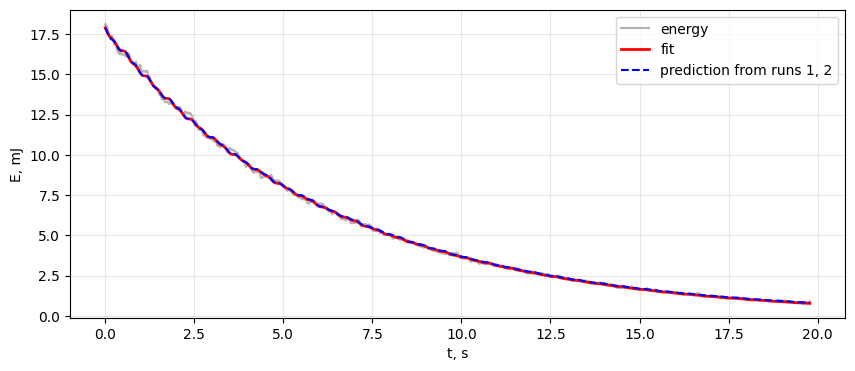

In [6]:
M1, M2 = single["cart1"]["m_eff"], single["cart2"]["m_eff"]

t, x1, x2 = load("both")
x1s, v1, nv1 = smooth_and_diff(t, x1)
x2s, v2, nv2 = smooth_and_diff(t, x2)
i0 = min(motion_start(t, v1, nv1), motion_start(t, v2, nv2))
t, x1s, x2s, v1, v2 = t[i0:] - t[i0], x1s[i0:], x2s[i0:], v1[i0:], v2[i0:]
x1s, x2s = x1s - x1s.mean(), x2s - x2s.mean()      # displacement from equilibrium

E = (0.5 * M1 * v1**2 + 0.5 * M2 * v2**2
     + 0.5 * k1 * x1s**2 + 0.5 * k12 * (x2s - x1s)**2 + 0.5 * k2 * x2s**2)
B1 = cumulative_trapezoid(v1**2 - nv1, t, initial=0)
B2 = cumulative_trapezoid(v2**2 - nv2, t, initial=0)
#B1 = cumulative_trapezoid(v1**2, t, initial=0)
#B2 = cumulative_trapezoid(v2**2, t, initial=0)

def viscous_energy_decay(t, b1, b2, E0):
    return -b1 * B1 - b2 * B2 + E0

parameters, pcov = curve_fit(viscous_energy_decay, t, E, p0=[0, 0, E[0]])
b1, b2, E0 = parameters
db1, db2, dE0 = np.sqrt(np.diag(pcov))
E_fitted = viscous_energy_decay(t, *parameters)
bs1, bs2 = single["cart1"]["b"], single["cart2"]["b"]
E_single = viscous_energy_decay(t, bs1, bs2, E0)        # prediction from runs 1 and 2

print(f"energy fit:  b1 = {b1:.3e} ± {db1:.1e},  b2 = {b2:.3e} ± {db2:.1e} kg/s")
print(f"runs 1, 2:   b1 = {bs1:.3e} ± {single['cart1']['db']:.1e},  b2 = {bs2:.3e} ± {single['cart2']['db']:.1e} kg/s")

plt.figure(figsize=(10, 4))
plt.plot(t, E * 1e3, color="0.7", label="energy")
plt.plot(t, E_fitted * 1e3, "r", lw=2, label="fit")
plt.plot(t, E_single * 1e3, "b--", lw=1.5, label="prediction from runs 1, 2")
plt.xlabel("t, s")
plt.ylabel("E, mJ")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Quality factors

**Carts** (the other one fixed): $Q_i = m_i^{\rm eff}\omega_i / b_i$, with $\omega_i$ from runs 1, 2.

**Normal modes**: eigenvalues $s=-\sigma\pm i\omega_d$ of $M\ddot x + D\dot x + Kx = 0$ with $M=\mathrm{diag}(m_1^{\rm eff}, m_2^{\rm eff})$, $D=\mathrm{diag}(b_1,b_2)$; $Q = |s|/(2\sigma)$.

In [ ]:
Mm = np.diag([M1, M2])
Km = np.array([[k1 + k12, -k12], [-k12, k2 + k12]])

def mode_Q(b1, b2):
    Dm = np.diag([b1, b2])
    A = np.block([[np.zeros((2, 2)), np.eye(2)],
                  [-np.linalg.solve(Mm, Km), -np.linalg.solve(Mm, Dm)]])
    s = np.linalg.eigvals(A)
    s = s[s.imag > 0]
    s = s[np.argsort(s.imag)]
    return s.imag / (2 * np.pi), np.abs(s) / (-2 * s.real)

print("carts:")
for i, (name, b, db) in enumerate([("cart1", b1, db1), ("cart2", b2, db2)]):
    r = single[name]
    Qe = r["m_eff"] * r["w0"] / b
    print(f"  cart {i+1}: Q = {Qe:.1f} ± {Qe*db/b:.1f} (energy fit),  {r['Q']:.1f} ± {r['dQ']:.1f} (run {i+1})")

f, Q = mode_Q(b1, b2)
samples = np.random.default_rng(1).multivariate_normal(parameters, pcov, 2000)
dQ = np.array([mode_Q(p[0], p[1])[1] for p in samples]).std(axis=0)
_, Qs = mode_Q(bs1, bs2)
print("normal modes:")
for i in range(2):
    print(f"  mode {i+1}: f = {f[i]:.4f} Hz,  Q = {Q[i]:.1f} ± {dQ[i]:.1f} (energy fit),  {Qs[i]:.1f} (from runs 1, 2)")

carts:
  cart 1: Q = 47.8 ± 0.8 (energy fit),  44.9 ± 0.0 (run 1)
  cart 2: Q = 53.2 ± 0.8 (energy fit),  56.8 ± 0.0 (run 2)
normal modes:
  mode 1: f = 0.7752 Hz,  Q = 30.9 ± 0.1 (energy fit),  30.6 (from runs 1, 2)
  mode 2: f = 1.6158 Hz,  Q = 64.5 ± 0.1 (energy fit),  65.1 (from runs 1, 2)
